

# Hito 2 — Modelos complementarios para supervisión de EPP

## Objetivo

El objetivo es complementar el sistema automatizado de monitoreo de EPP desarrollado en el Certamen 2 mediante dos componentes:

1. **Series temporales:** pronosticar la cantidad diaria de trabajadores con al menos un EPP no confirmado por zona, comparando un modelo ingenuo estacional, Holt-Winters y LSTM.
2. **Clasificación de texto:** clasificar reportes escritos de seguridad mediante embeddings de un Transformer preentrenado, comparando su desempeño con reglas de palabras clave.

Ambos análisis buscan aportar información adicional para apoyar la supervisión y la toma de decisiones preventivas.

## Origen de los datos

Se utiliza el archivo `Hito2_Dataset_Sintetico_EPP_v3.zip`, generado específicamente para el proyecto con semilla 20261115.

Dado que el sistema implementado en el Certamen 2 aún no cuenta con un historial extenso de inspecciones, se generaron datos sintéticos para representar un año de registros de supervisión.

La simulación considera las mismas dos zonas de trabajo del sistema y variables equivalentes a las almacenadas automáticamente en Google Sheets, como trabajadores detectados y trabajadores que requieren revisión.

Para el análisis temporal, los registros se encuentran agrupados por fecha y zona, mientras que Google Sheets almacena una fila por inspección.

La variable objetivo, `trabajadores_revision`, corresponde a trabajadores detectados con al menos un EPP obligatorio no confirmado. Esta situación puede deberse a la ausencia del elemento o a limitaciones de detección, por lo que no representa incumplimientos confirmados.

Los datos son 100 % simulados: no corresponden a inspecciones reales procesadas por YOLO. En consecuencia, los resultados permiten desarrollar y comparar modelos, pero no garantizan su desempeño futuro en una instalación industrial.

## Referencias metodológicas

El desarrollo se basa en los contenidos revisados en clases:

- **Series temporales:** modelos clásicos y LSTM, siguiendo la metodología de la plantilla AirPassengers.
- **Procesamiento de texto:** embeddings de Transformers y comparación con reglas simples del módulo NLP.



# 1. Carga y preparación inicial de los datos

En esta etapa se cargan desde el archivo ZIP los datos sintéticos necesarios para los dos análisis del Hito 2.

El conjunto contiene:

- **730 registros de series temporales:** 365 días para cada una de las dos zonas, desde noviembre de 2025 hasta octubre de 2026.
- **1.460 reportes textuales:** descripciones simuladas de situaciones de seguridad.
- **Particiones de datos:** utilizadas posteriormente para separar entrenamiento, validación y prueba.

Los registros temporales representan resultados diarios agregados, equivalentes a los que podrían obtenerse agrupando por fecha y zona el historial de inspecciones almacenado en Google Sheets.

Se revisa la carga de los archivos, se convierten las fechas y se observa la estructura inicial de los datos antes de desarrollar los modelos.


In [ ]:

# 1. Cargar los datos de inspecciones de EPP

import pandas as pd
import zipfile
import io
from google.colab import files

# Subir el archivo ZIP del dataset
archivos = files.upload()

nombre_zip = next(
    nombre for nombre in archivos
    if nombre.lower().endswith(".zip")
)

# Leer los archivos directamente desde el ZIP
with zipfile.ZipFile(io.BytesIO(archivos[nombre_zip])) as zip_ref:

    serie = pd.read_csv(
        zip_ref.open("serie_diaria_por_zona_simulada.csv")
    )

    reportes = pd.read_csv(
        zip_ref.open("reportes_textuales_simulados.csv")
    )

    particiones = pd.read_csv(
        zip_ref.open("particiones_temporales.csv")
    )

# Convertir las fechas
serie["fecha"] = pd.to_datetime(serie["fecha"])

# Revisar los datos cargados
print("Registros de serie temporal:", len(serie))
print("Reportes textuales:", len(reportes))
print("Zonas:", serie["zona_id"].unique())

display(serie.head())


Saving Hito2_Dataset_Sintetico_EPP_v3.zip to Hito2_Dataset_Sintetico_EPP_v3.zip
Registros de serie temporal: 730
Reportes textuales: 1460
Zonas: ['zona_1' 'zona_2']


,fuente_datos,fecha,zona_id,inspecciones,personas_detectadas,personas_evaluables,trabajadores_revision,epp_no_confirmados,eventos_reportados,trabajadores_simulados,tasa_revision_potencial_pct,tasa_eventos_simulados_pct,dia_semana,mes
0,SIMULADO,2025-11-01,zona_1,2,15,15,13,17,0,16,86.67,0.0,5,11
1,SIMULADO,2025-11-01,zona_2,2,15,15,13,28,0,18,86.67,0.0,5,11
2,SIMULADO,2025-11-02,zona_1,2,10,10,7,9,0,11,70.00,0.0,6,11
3,SIMULADO,2025-11-02,zona_2,2,9,9,8,20,0,10,88.89,0.0,6,11
4,SIMULADO,2025-11-03,zona_1,2,11,11,6,7,0,15,54.55,0.0,0,11




## 2. Exploración de la serie temporal

Se analiza la evolución diaria de `trabajadores_revision` para cada zona, considerando los 365 días del historial simulado.

Esta variable representa la cantidad de trabajadores detectados con al menos un EPP obligatorio no confirmado, por lo que corresponde a casos potenciales de revisión humana y no a incumplimientos comprobados.

Se calculan estadísticas descriptivas y se grafica la evolución de ambas zonas para identificar diferencias en sus niveles, variabilidad y posibles patrones temporales antes del entrenamiento de los modelos.


Resumen de trabajadores que requieren revision:


,count,mean,min,max,std
zona_id,,,,,
zona_1,365,7.04,2,14,2.32
zona_2,365,9.68,2,17,2.55


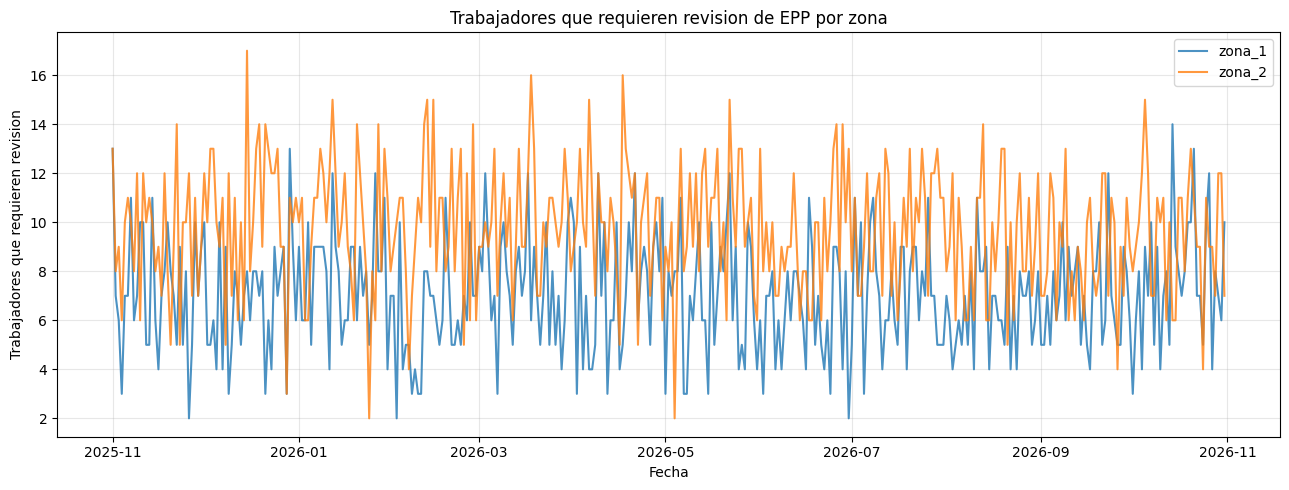

In [ ]:

# 2. Explorar la serie temporal por zona

import matplotlib.pyplot as plt

# Ordenar los registros por fecha
serie = serie.sort_values(["zona_id", "fecha"]).copy()

# Resumen estadistico de la variable que queremos pronosticar
resumen = serie.groupby("zona_id")["trabajadores_revision"].agg(
    ["count", "mean", "min", "max", "std"]
).round(2)

print("Resumen de trabajadores que requieren revision:")
display(resumen)

# Visualizar la evolucion diaria
plt.figure(figsize=(13, 5))

for zona in serie["zona_id"].unique():
    datos_zona = serie[serie["zona_id"] == zona]

    plt.plot(
        datos_zona["fecha"],
        datos_zona["trabajadores_revision"],
        label=zona,
        alpha=0.8
    )

plt.title("Trabajadores que requieren revision de EPP por zona")
plt.xlabel("Fecha")
plt.ylabel("Trabajadores que requieren revision")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Interpretación de los resultados

Durante los 365 días simulados, la zona 1 presenta un promedio de 7,04 trabajadores diarios que requieren revisión, mientras que la zona 2 alcanza 9,68.

Esta diferencia debe interpretarse considerando que las zonas tienen distintos EPP obligatorios y que los datos fueron generados bajo supuestos de detección diferentes. Por lo tanto, una mayor cantidad de casos no implica necesariamente un mayor incumplimiento de seguridad.

Ambas series presentan fluctuaciones diarias, con desviaciones estándar de 2,32 y 2,55 trabajadores, respectivamente. En el gráfico no se observa una tendencia creciente o decreciente evidente, aunque podrían existir patrones temporales que no se distinguen fácilmente mediante una inspección visual.

Estos resultados justifican evaluar distintos modelos de pronóstico y comparar su capacidad predictiva utilizando las mismas observaciones.




## 3. Separación de entrenamiento, validación y prueba

Como trabajamos con series temporales, los registros se dividen respetando su orden cronológico. De esta manera, evitamos utilizar información futura para entrenar modelos que deben pronosticar valores posteriores.

Se utilizan las particiones temporales definidas en el dataset sintético:

- **Entrenamiento (255 días):** permite ajustar los parámetros de los modelos.
- **Validación (55 días):** permite comparar alternativas y seleccionar el modelo con mejor desempeño.
- **Prueba (55 días):** permite evaluar finalmente el modelo seleccionado con datos que no participaron en su entrenamiento ni selección.

Se aplican los mismos períodos a ambas zonas para mantener una comparación consistente.

In [ ]:

# 3. Separar los datos segun las particiones del dataset

# Preparar la fecha del archivo de particiones
particiones["fecha"] = pd.to_datetime(particiones["fecha"])

# Incorporar la particion correspondiente a cada fecha
serie = serie.merge(
    particiones[["fecha", "particion"]],
    on="fecha",
    how="left",
    validate="many_to_one"
)

# Verificar que todos los registros tengan particion
assert serie["particion"].notna().all(), \
    "Hay fechas sin particion asignada"

# Revisar los periodos y cantidad de dias
resumen_particiones = particiones.groupby("particion")["fecha"].agg(
    ["count", "min", "max"]
)

print("Periodos definidos para el analisis:")
display(resumen_particiones)

# Separar los datos
train = serie[serie["particion"] == "train"].copy()
val = serie[serie["particion"] == "val"].copy()
test = serie[serie["particion"] == "test"].copy()

print("Registros de entrenamiento:", len(train))
print("Registros de validacion:", len(val))
print("Registros de prueba:", len(test))


Periodos definidos para el analisis:


,count,min,max
particion,,,
test,55,2026-09-07,2026-10-31
train,255,2025-11-01,2026-07-13
val,55,2026-07-14,2026-09-06


Registros de entrenamiento: 510
Registros de validacion: 110
Registros de prueba: 110


### Verificación de las particiones

Se obtuvieron 510 registros de entrenamiento, 110 de validación y 110 de prueba. Como el dataset contiene dos zonas con una observación diaria cada una, estos valores corresponden a 255, 55 y 55 días por zona, respectivamente.

Las particiones cubren el período completo entre noviembre de 2025 y octubre de 2026, sin fechas faltantes en la asignación.

Esta separación permite comparar los modelos utilizando períodos equivalentes y reservar los datos de prueba para la evaluación final.



## 4. Modelos de pronóstico

Se compararán dos modelos para pronosticar la cantidad diaria de trabajadores que requieren revisión de EPP:

**Modelo ingenuo estacional:** utiliza los valores de los últimos siete días y repite ese patrón para pronosticar los días siguientes. Se utiliza como referencia para evaluar si un modelo más elaborado aporta mejoras.

**Holt-Winters:** utiliza suavizamiento exponencial para estimar el nivel de la serie y su estacionalidad semanal. Se considera un período de siete días debido a la frecuencia diaria de los registros, sin incorporar una tendencia explícita.

Ambos modelos se evaluarán mediante MAE y RMSE, donde valores menores indican errores de pronóstico más bajos.

Primero se ajustarán utilizando entrenamiento y se pronosticarán los 55 días de validación. Luego se utilizarán entrenamiento y validación para pronosticar los 55 días de prueba. En ambos casos, los pronósticos se realizan sin utilizar los valores reales del período que se está evaluando.


In [ ]:

# 4. Comparacion del modelo ingenuo estacional y Holt-Winters

import numpy as np
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Modelo base: repetir el comportamiento de los ultimos 7 dias
def modelo_ingenuo(datos, pasos):
    ultimos_7 = datos[-7:]
    return np.resize(ultimos_7, pasos)

# Modelo Holt-Winters con estacionalidad semanal
def modelo_holt_winters(datos, pasos):
    modelo = ExponentialSmoothing(
        datos,
        trend=None,
        seasonal="add",
        seasonal_periods=7
    )

    ajuste = modelo.fit()
    prediccion = ajuste.forecast(pasos)

    # No puede haber una cantidad negativa de trabajadores
    return np.maximum(prediccion, 0)

# Calcular los errores de pronostico
def calcular_errores(reales, predichos):
    mae = np.mean(np.abs(reales - predichos))
    rmse = np.sqrt(np.mean((reales - predichos) ** 2))
    return round(mae, 2), round(rmse, 2)

resultados = []

for zona in ["zona_1", "zona_2"]:

    datos_zona = serie[serie["zona_id"] == zona].sort_values("fecha")

    entrenamiento = datos_zona[
        datos_zona["particion"] == "train"
    ]["trabajadores_revision"].to_numpy(dtype=float)

    validacion = datos_zona[
        datos_zona["particion"] == "val"
    ]["trabajadores_revision"].to_numpy(dtype=float)

    prueba = datos_zona[
        datos_zona["particion"] == "test"
    ]["trabajadores_revision"].to_numpy(dtype=float)

    # Primero evaluar usando entrenamiento y validacion
    for nombre, funcion in [
        ("Ingenuo estacional", modelo_ingenuo),
        ("Holt-Winters", modelo_holt_winters)
    ]:

        pred_val = funcion(entrenamiento, len(validacion))
        mae, rmse = calcular_errores(validacion, pred_val)

        resultados.append({
            "Zona": zona,
            "Conjunto": "Validacion",
            "Modelo": nombre,
            "MAE": mae,
            "RMSE": rmse
        })

        # Para la prueba final se utilizan train + val
        datos_ajuste = np.concatenate([entrenamiento, validacion])

        pred_test = funcion(datos_ajuste, len(prueba))
        mae, rmse = calcular_errores(prueba, pred_test)

        resultados.append({
            "Zona": zona,
            "Conjunto": "Prueba",
            "Modelo": nombre,
            "MAE": mae,
            "RMSE": rmse
        })

# Tabla comparativa
resultados_modelos = pd.DataFrame(resultados)

print("Resultados de validacion:")
display(
    resultados_modelos[
        resultados_modelos["Conjunto"] == "Validacion"
    ]
)

print("Resultados de prueba:")
display(
    resultados_modelos[
        resultados_modelos["Conjunto"] == "Prueba"
    ]
)


Resultados de validacion:


,Zona,Conjunto,Modelo,MAE,RMSE
0,zona_1,Validacion,Ingenuo estacional,2.31,2.84
2,zona_1,Validacion,Holt-Winters,1.54,1.86
4,zona_2,Validacion,Ingenuo estacional,2.80,3.46
6,zona_2,Validacion,Holt-Winters,2.01,2.41


Resultados de prueba:


,Zona,Conjunto,Modelo,MAE,RMSE
1,zona_1,Prueba,Ingenuo estacional,2.33,3.05
3,zona_1,Prueba,Holt-Winters,1.94,2.43
5,zona_2,Prueba,Ingenuo estacional,2.85,3.45
7,zona_2,Prueba,Holt-Winters,2.00,2.40



### Interpretación de los resultados

Holt-Winters obtuvo menores errores que el modelo ingenuo estacional en ambas zonas, tanto en validación como en prueba.

En validación, el MAE de Holt-Winters fue de 1,54 para la zona 1 y 2,01 para la zona 2, frente a 2,31 y 2,80 del modelo ingenuo, respectivamente.

En prueba, Holt-Winters también presentó menores errores, con un MAE de 1,94 en la zona 1 y 2,00 en la zona 2. El RMSE fue igualmente menor en ambas zonas.

Esto indica que, en el historial simulado, Holt-Winters logra aprovechar mejor los patrones temporales que una simple repetición de los últimos siete días.

Por lo tanto, Holt-Winters es la mejor alternativa entre los dos modelos evaluados hasta ahora. Sin embargo, todavía falta compararlo con LSTM para determinar si una red neuronal permite mejorar los pronósticos.

Estos resultados corresponden al conjunto sintético utilizado y no garantizan el mismo desempeño con inspecciones reales.


## 5. Modelo LSTM

Se implementa una red neuronal LSTM para pronosticar la cantidad diaria de trabajadores que requieren revisión de EPP en cada zona.

A diferencia de Holt-Winters, la red aprende patrones a partir de secuencias de observaciones anteriores. En este caso, se utilizan ventanas de 14 días para predecir el valor del día siguiente.

Los datos se normalizan utilizando inicialmente solo el conjunto de entrenamiento, para evitar incorporar información futura durante el ajuste.

Se utiliza la pérdida de validación para seleccionar la cantidad de épocas mediante Early Stopping. Luego, se entrena un modelo final con entrenamiento y validación, reservando los datos de prueba para la evaluación.

Para comparar los métodos bajo condiciones equivalentes, la LSTM genera pronósticos recursivos de 55 días sin utilizar los valores reales futuros durante la predicción.

Finalmente, se comparan sus errores mediante MAE y RMSE con Holt-Winters y el modelo ingenuo estacional.


In [ ]:

# 5. Modelo LSTM para pronosticar trabajadores que requieren revision

import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

VENTANA = 14

# Preparar secuencias de 14 dias para entrenar la red
def crear_ventanas(datos):
    X, y = [], []

    for i in range(VENTANA, len(datos)):
        X.append(datos[i-VENTANA:i])
        y.append(datos[i])

    return (
        np.array(X).reshape(-1, VENTANA, 1),
        np.array(y)
    )

# Crear la arquitectura LSTM
def crear_modelo():
    modelo = Sequential([
        Input(shape=(VENTANA, 1)),
        LSTM(16),
        Dense(1)
    ])

    modelo.compile(
        optimizer="adam",
        loss="mse"
    )

    return modelo

# Pronosticar varios dias sin utilizar los valores reales futuros
def pronosticar_lstm(modelo, scaler, historia, pasos):
    historia_normalizada = scaler.transform(
        np.array(historia).reshape(-1, 1)
    ).flatten().tolist()

    predicciones = []

    for _ in range(pasos):
        ventana = np.array(
            historia_normalizada[-VENTANA:]
        ).reshape(1, VENTANA, 1)

        siguiente = float(
            modelo.predict(ventana, verbose=0)[0][0]
        )

        historia_normalizada.append(siguiente)
        predicciones.append(siguiente)

    predicciones = scaler.inverse_transform(
        np.array(predicciones).reshape(-1, 1)
    ).flatten()

    return np.maximum(predicciones, 0)

resultados_lstm = []

for zona in ["zona_1", "zona_2"]:

    print("\nEntrenando LSTM para", zona)

    datos_zona = serie[
        serie["zona_id"] == zona
    ].sort_values("fecha")

    train_zona = datos_zona[
        datos_zona["particion"] == "train"
    ]["trabajadores_revision"].to_numpy(dtype=float)

    val_zona = datos_zona[
        datos_zona["particion"] == "val"
    ]["trabajadores_revision"].to_numpy(dtype=float)

    test_zona = datos_zona[
        datos_zona["particion"] == "test"
    ]["trabajadores_revision"].to_numpy(dtype=float)

    # Normalizacion usando solamente entrenamiento
    scaler = MinMaxScaler()

    train_normalizado = scaler.fit_transform(
        train_zona.reshape(-1, 1)
    ).flatten()

    # Ventanas para entrenamiento
    X_train, y_train = crear_ventanas(train_normalizado)

    # Ventanas de validacion, con los ultimos dias de train
    datos_val = np.concatenate([
        train_zona[-VENTANA:],
        val_zona
    ])

    val_normalizado = scaler.transform(
        datos_val.reshape(-1, 1)
    ).flatten()

    X_val, y_val = crear_ventanas(val_normalizado)

    # Entrenamiento inicial para seleccionar las epocas
    modelo = crear_modelo()

    historial = modelo.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=16,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=6,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    mejor_epoca = int(
        np.argmin(historial.history["val_loss"]) + 1
    )

    # Pronostico de validacion sin conocer datos futuros
    pred_val = pronosticar_lstm(
        modelo, scaler, train_zona, len(val_zona)
    )

    mae_val, rmse_val = calcular_errores(
        val_zona, pred_val
    )

    resultados_lstm.append({
        "Zona": zona,
        "Conjunto": "Validacion",
        "Modelo": "LSTM",
        "MAE": mae_val,
        "RMSE": rmse_val
    })

    # Entrenar el modelo final con train + validacion
    datos_ajuste = np.concatenate([
        train_zona, val_zona
    ])

    scaler_final = MinMaxScaler()

    ajuste_normalizado = scaler_final.fit_transform(
        datos_ajuste.reshape(-1, 1)
    ).flatten()

    X_final, y_final = crear_ventanas(ajuste_normalizado)

    modelo_final = crear_modelo()

    modelo_final.fit(
        X_final,
        y_final,
        epochs=mejor_epoca,
        batch_size=16,
        verbose=0
    )

    # Pronosticar los 55 dias de prueba
    pred_test = pronosticar_lstm(
        modelo_final,
        scaler_final,
        datos_ajuste,
        len(test_zona)
    )

    mae_test, rmse_test = calcular_errores(
        test_zona, pred_test
    )

    resultados_lstm.append({
        "Zona": zona,
        "Conjunto": "Prueba",
        "Modelo": "LSTM",
        "MAE": mae_test,
        "RMSE": rmse_test
    })

    print("Mejor epoca:", mejor_epoca)
    print("MAE validacion:", mae_val)
    print("MAE prueba:", mae_test)

# Comparar los tres modelos
resultados_lstm = pd.DataFrame(resultados_lstm)

comparacion_final = pd.concat(
    [resultados_modelos, resultados_lstm],
    ignore_index=True
)

print("\nComparacion final en prueba:")

display(
    comparacion_final[
        comparacion_final["Conjunto"] == "Prueba"
    ].sort_values(["Zona", "MAE"])
)



Entrenando LSTM para zona_1
Mejor epoca: 31
MAE validacion: 1.46
MAE prueba: 1.88

Entrenando LSTM para zona_2
Mejor epoca: 4
MAE validacion: 2.12
MAE prueba: 1.94

Comparacion final en prueba:


,Zona,Conjunto,Modelo,MAE,RMSE
9,zona_1,Prueba,LSTM,1.88,2.41
3,zona_1,Prueba,Holt-Winters,1.94,2.43
1,zona_1,Prueba,Ingenuo estacional,2.33,3.05
11,zona_2,Prueba,LSTM,1.94,2.34
7,zona_2,Prueba,Holt-Winters,2.00,2.40
5,zona_2,Prueba,Ingenuo estacional,2.85,3.45


In [ ]:

# Seleccionar el modelo con menor MAE de validacion por zona
seleccion_modelos = (
    comparacion_final[
        comparacion_final["Conjunto"] == "Validacion"
    ]
    .sort_values(["Zona", "MAE", "RMSE"])
    .groupby("Zona", as_index=False)
    .first()[["Zona", "Modelo", "MAE", "RMSE"]]
)

print("Modelos seleccionados segun validacion:")
display(seleccion_modelos)


Modelos seleccionados segun validacion:


,Zona,Modelo,MAE,RMSE
0,zona_1,LSTM,1.46,1.77
1,zona_2,Holt-Winters,2.01,2.41



### Comparación final y selección de modelos

Se compararon tres modelos para pronosticar la cantidad diaria de trabajadores que requieren revisión de EPP: ingenuo estacional, Holt-Winters y LSTM.

En validación, LSTM obtuvo el menor MAE en la zona 1 (1,46), mientras que Holt-Winters presentó el menor error en la zona 2 (2,01). Por esta razón, se seleccionaron LSTM para la zona 1 y Holt-Winters para la zona 2.

En prueba, LSTM obtuvo el menor MAE en ambas zonas, con 1,88 en la zona 1 y 1,94 en la zona 2. Sin embargo, la diferencia respecto de Holt-Winters fue de solo 0,06 trabajadores en promedio por día.

Esto indica que la mayor complejidad de LSTM no se tradujo en una mejora importante frente al modelo clásico. Por lo tanto, se mantiene la selección realizada mediante validación, sin utilizar los resultados de prueba para modificarla.

Los resultados corresponden a datos sintéticos y deberán reevaluarse cuando exista un historial suficiente de inspecciones reales.



# Análisis de reportes de incidentes mediante Transformers

## 6. Exploración de los reportes textuales

Para incorporar información no estructurada al sistema de supervisión de EPP, se analizarán reportes preventivos escritos en lenguaje natural.

El objetivo es clasificar los reportes según el tipo de evento descrito, de manera que esta información pueda complementar los resultados del reconocimiento de imágenes y apoyar las recomendaciones preventivas del sistema.

Se utilizarán 1.460 reportes sintéticos asociados a las dos zonas de trabajo, distribuidos en cinco categorías: sin evento reportado, contacto con objetos, caídas, exposición a sustancias y transporte.

Se comparará una clasificación mediante reglas de palabras clave con un modelo basado en embeddings de un Transformer preentrenado, para evaluar si el análisis del significado de los textos ofrece mejoras frente a una solución basada en palabras específicas.

Antes de desarrollar los clasificadores, se revisará la distribución de las categorías y se mantendrá la separación cronológica de entrenamiento, validación y prueba.


In [ ]:

# 6. Exploracion de los reportes textuales

# Preparar fechas
reportes["fecha"] = pd.to_datetime(reportes["fecha"])

# Agregar las particiones temporales ya definidas
if "particion" not in reportes.columns:
    reportes = reportes.merge(
        particiones[["fecha", "particion"]],
        on="fecha",
        how="left",
        validate="many_to_one"
    )

# Comprobar que todos los reportes tengan particion
assert reportes["particion"].notna().all()

print("Cantidad total de reportes:", len(reportes))

# Contar las categorias existentes
print("\nReportes por categoria:")
display(
    reportes["categoria_evento_simulado"]
    .value_counts()
    .to_frame("Cantidad")
)

# Revisar la distribucion por particion
print("\nCategorias por conjunto de datos:")
display(
    pd.crosstab(
        reportes["categoria_evento_simulado"],
        reportes["particion"]
    )
)

# Ver ejemplos de los textos y sus categorias
print("\nEjemplos de reportes:")
display(
    reportes[
        ["zona_id", "texto", "categoria_evento_simulado"]
    ].head(8)
)


Cantidad total de reportes: 1460

Reportes por categoria:


,Cantidad
categoria_evento_simulado,
sin_evento_reportado,1296
contacto_objetos,70
caidas,38
exposicion_sustancias,31
transporte,25



Categorias por conjunto de datos:


particion,test,train,val
categoria_evento_simulado,,,
caidas,4,26,8
contacto_objetos,12,50,8
exposicion_sustancias,3,23,5
sin_evento_reportado,198,901,197
transporte,3,20,2



Ejemplos de reportes:


,zona_id,texto,categoria_evento_simulado
0,zona_1,Registro del turno: La supervisión transcurrió...,sin_evento_reportado
1,zona_1,Se dejó constancia: El control rutinario final...,sin_evento_reportado
2,zona_2,Bitácora operacional: El control rutinario fin...,sin_evento_reportado
3,zona_2,Durante la supervisión: El control rutinario f...,sin_evento_reportado
4,zona_1,Se dejó constancia: No hubo observaciones adic...,sin_evento_reportado
5,zona_1,Bitácora operacional: No hubo observaciones ad...,sin_evento_reportado
6,zona_2,En el recorrido: El control rutinario finalizó...,sin_evento_reportado
7,zona_2,Bitácora operacional: La supervisión transcurr...,sin_evento_reportado



### Interpretación de los datos

La base contiene 1.460 reportes simulados, clasificados en cinco categorías: sin evento reportado, contacto con objetos, caídas, exposición a sustancias y transporte.

La distribución está desbalanceada: 1.296 reportes (88,8 %) corresponden a situaciones sin eventos adicionales, mientras que las otras cuatro categorías presentan frecuencias considerablemente menores.

Por este motivo, no utilizaremos únicamente accuracy para evaluar los modelos, ya que un clasificador podría obtener un porcentaje elevado de aciertos simplemente prediciendo la categoría mayoritaria.

Se priorizará F1-macro, complementado con precision y recall por categoría, para evaluar también la capacidad de identificar los eventos menos frecuentes.

Los datos se dividieron cronológicamente en 1.020 reportes de entrenamiento, 220 de validación y 220 de prueba.

Una limitación importante es que los textos fueron generados mediante estructuras y expresiones sintéticas similares. Además, algunas categorías cuentan con muy pocos ejemplos en prueba, por lo que sus métricas pueden variar considerablemente ante pequeños cambios en las predicciones.

Por lo tanto, los resultados permitirán comparar los clasificadores dentro de este experimento, pero no garantizarán su desempeño con reportes reales escritos por supervisores.


## 2. Clasificación mediante reglas

Como alternativa simple, se implementa un clasificador basado en palabras clave para identificar el tipo de evento descrito en cada reporte.

El código normaliza los textos y busca términos asociados a cuatro categorías: caídas, contacto con objetos, exposición a sustancias y transporte. Cuando no encuentra coincidencias, asigna la categoría `sin_evento_reportado`.

Este método no requiere entrenamiento, ya que utiliza reglas definidas previamente. Sin embargo, depende de las expresiones utilizadas y no interpreta necesariamente el contexto de los reportes.

Se evaluará mediante accuracy y F1-macro en los conjuntos de validación y prueba, para establecer una referencia frente al modelo basado en Transformer.

In [ ]:

# 7. Clasificacion de reportes mediante palabras clave

import unicodedata
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Normalizar los textos para comparar palabras
def normalizar(texto):
    texto = str(texto).lower()

    texto = "".join(
        caracter for caracter in
        unicodedata.normalize("NFD", texto)
        if unicodedata.category(caracter) != "Mn"
    )

    return texto

# Definir las palabras asociadas a cada categoria
palabras_clave = {
    "caidas": [
        "caida", "resbal", "tropiezo",
        "desnivel", "obstaculo", "superficie irregular"
    ],

    "contacto_objetos": [
        "objetos en movimiento", "golpe por objeto",
        "contacto con maquinaria", "contacto con herramientas",
        "proximidad a equipos"
    ],

    "exposicion_sustancias": [
        "polvo", "particulas", "material particulado",
        "salpicaduras"
    ],

    "transporte": [
        "vehiculos", "transito", "peatones",
        "visibilidad reducida", "paso de maquinaria"
    ]
}

# Clasificar un reporte
def clasificar_reglas(texto):
    texto = normalizar(texto)

    for categoria, palabras in palabras_clave.items():
        if any(palabra in texto for palabra in palabras):
            return categoria

    return "sin_evento_reportado"

# Evaluar el modelo en validacion y prueba
resultados_reglas = []

for conjunto in ["val", "test"]:

    datos = reportes[
        reportes["particion"] == conjunto
    ].copy()

    reales = datos["categoria_evento_simulado"]

    predichos = datos["texto"].apply(clasificar_reglas)

    accuracy = accuracy_score(reales, predichos)
    f1_macro = f1_score(
        reales, predichos, average="macro", zero_division=0
    )

    resultados_reglas.append({
        "Modelo": "Reglas",
        "Conjunto": conjunto,
        "Accuracy": round(accuracy, 3),
        "F1-macro": round(f1_macro, 3)
    })

    print("\nResultados del conjunto:", conjunto)
    print("Accuracy:", round(accuracy, 3))
    print("F1-macro:", round(f1_macro, 3))

    print("\nResultados por categoria:")
    print(
        classification_report(
            reales,
            predichos,
            zero_division=0
        )
    )

# Guardar los resultados para compararlos con Transformer
resultados_reglas = pd.DataFrame(resultados_reglas)

display(resultados_reglas)



Resultados del conjunto: val
Accuracy: 0.905
F1-macro: 0.39

Resultados por categoria:
                       precision    recall  f1-score   support

               caidas       0.00      0.00      0.00         8
     contacto_objetos       0.00      0.00      0.00         8
exposicion_sustancias       1.00      0.20      0.33         5
 sin_evento_reportado       0.90      1.00      0.95       197
           transporte       1.00      0.50      0.67         2

             accuracy                           0.90       220
            macro avg       0.58      0.34      0.39       220
         weighted avg       0.84      0.90      0.86       220


Resultados del conjunto: test
Accuracy: 0.9
F1-macro: 0.189

Resultados por categoria:
                       precision    recall  f1-score   support

               caidas       0.00      0.00      0.00         4
     contacto_objetos       0.00      0.00      0.00        12
exposicion_sustancias       0.00      0.00      0.00         3
 

,Modelo,Conjunto,Accuracy,F1-macro
0,Reglas,val,0.905,0.390
1,Reglas,test,0.900,0.189


### Interpretación de los resultados

El clasificador basado en palabras clave obtuvo un accuracy de 90 % y un F1-macro de 0,189 en el conjunto de prueba.

Aunque el accuracy parece elevado, el análisis por categoría muestra que identificó correctamente los 198 reportes sin eventos, pero no reconoció ninguno de los 22 reportes correspondientes a las otras cuatro categorías.

Esto se explica principalmente por el desbalance de los datos y la dependencia de palabras específicas. Cuando los reportes utilizan expresiones distintas de las definidas en las reglas, el clasificador puede no identificar el evento descrito.

Además, el F1-macro disminuyó de 0,390 en validación a 0,189 en prueba, mostrando diferencias de desempeño entre ambos conjuntos.

Por lo tanto, el modelo basado en reglas presenta limitaciones para reconocer las distintas categorías de incidentes. Estos resultados se utilizarán como referencia para evaluar si el modelo basado en embeddings de Transformer consigue mejorar la clasificación.


## 3. Clasificación mediante Transformer

Para comparar el clasificador basado en reglas con una alternativa de mayor complejidad, se utiliza un Transformer multilingüe preentrenado.

El modelo `paraphrase-multilingual-MiniLM-L12-v2` convierte los reportes en embeddings, es decir, representaciones numéricas que permiten analizar similitudes en el significado de los textos.

Posteriormente, se entrena una regresión logística para clasificar estos embeddings en las cinco categorías definidas. Se utiliza `class_weight="balanced"` debido al desbalance observado entre las categorías.

Se mantienen las mismas particiones temporales utilizadas anteriormente. El clasificador se entrena con el conjunto de entrenamiento y se evalúa mediante accuracy y F1-macro en validación y prueba.

El objetivo es determinar si este enfoque permite reconocer mejor las distintas situaciones descritas en los reportes, en comparación con las reglas de palabras clave.


In [ ]:
%pip -q install sentence-transformers

In [ ]:

# 8. Clasificacion de reportes utilizando Transformer

import numpy as np
import pandas as pd

from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# 1. Cargar el modelo Transformer preentrenado
modelo_transformer = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

# 2. Obtener los textos distintos
textos_unicos = reportes["texto"].astype(str).unique().tolist()

print("Reportes totales:", len(reportes))
print("Textos distintos:", len(textos_unicos))

# 3. Convertir los textos en embeddings
embeddings = modelo_transformer.encode(
    textos_unicos,
    batch_size=16,
    show_progress_bar=True,
    normalize_embeddings=True
)

# Asociar cada texto con su embedding
vectores = dict(zip(textos_unicos, embeddings))

# 4. Separar los conjuntos de datos
train_texto = reportes[
    reportes["particion"] == "train"
].copy()

val_texto = reportes[
    reportes["particion"] == "val"
].copy()

test_texto = reportes[
    reportes["particion"] == "test"
].copy()

# Recuperar los embeddings de cada conjunto
def obtener_vectores(datos):
    return np.vstack([
        vectores[str(texto)]
        for texto in datos["texto"]
    ])

X_train = obtener_vectores(train_texto)
X_val = obtener_vectores(val_texto)
X_test = obtener_vectores(test_texto)

y_train = train_texto["categoria_evento_simulado"]
y_val = val_texto["categoria_evento_simulado"]
y_test = test_texto["categoria_evento_simulado"]

# 5. Entrenar el clasificador
clasificador_transformer = LogisticRegression(
    max_iter=1200,
    class_weight="balanced",
    random_state=42
)

clasificador_transformer.fit(X_train, y_train)

# 6. Evaluar en validacion y prueba
resultados_transformer = []

for conjunto, X, y in [
    ("val", X_val, y_val),
    ("test", X_test, y_test)
]:

    predicciones = clasificador_transformer.predict(X)

    accuracy = accuracy_score(y, predicciones)

    f1_macro = f1_score(
        y,
        predicciones,
        average="macro",
        zero_division=0
    )

    resultados_transformer.append({
        "Modelo": "Transformer",
        "Conjunto": conjunto,
        "Accuracy": round(accuracy, 3),
        "F1-macro": round(f1_macro, 3)
    })

    print("\nResultados Transformer:", conjunto)
    print("Accuracy:", round(accuracy, 3))
    print("F1-macro:", round(f1_macro, 3))

    print("\nResultados por categoria:")
    print(
        classification_report(
            y,
            predicciones,
            zero_division=0
        )
    )

# 7. Comparar con el modelo basado en reglas
resultados_transformer = pd.DataFrame(resultados_transformer)

comparacion_texto = pd.concat(
    [resultados_reglas, resultados_transformer],
    ignore_index=True
)

print("\nComparacion final de modelos:")
display(comparacion_texto)


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (7 outputs left out)

Reportes totales: 1460
Textos distintos: 1207


Batches:   0%|          | 0/76 [00:00<?, ?it/s]


Resultados Transformer: val
Accuracy: 0.982
F1-macro: 0.837

Resultados por categoria:
                       precision    recall  f1-score   support

               caidas       0.89      1.00      0.94         8
     contacto_objetos       1.00      0.50      0.67         8
exposicion_sustancias       0.83      1.00      0.91         5
 sin_evento_reportado       1.00      1.00      1.00       197
           transporte       0.50      1.00      0.67         2

             accuracy                           0.98       220
            macro avg       0.84      0.90      0.84       220
         weighted avg       0.99      0.98      0.98       220


Resultados Transformer: test
Accuracy: 0.986
F1-macro: 0.905

Resultados por categoria:
                       precision    recall  f1-score   support

               caidas       1.00      1.00      1.00         4
     contacto_objetos       1.00      0.75      0.86        12
exposicion_sustancias       1.00      1.00      1.00         3


,Modelo,Conjunto,Accuracy,F1-macro
0,Reglas,val,0.905,0.390
1,Reglas,test,0.900,0.189
2,Transformer,val,0.982,0.837
3,Transformer,test,0.986,0.905



### Comparación final y selección del modelo

Se comparó el clasificador basado en palabras clave con un modelo que utiliza embeddings de un Transformer multilingüe preentrenado y regresión logística.

En validación, el modelo basado en reglas obtuvo un F1-macro de 0,390, mientras que el Transformer alcanzó 0,837. Esta diferencia permitió seleccionar el Transformer como la alternativa con mejor desempeño.

Posteriormente, en el conjunto de prueba, el modelo de reglas obtuvo un accuracy de 0,900 y un F1-macro de 0,189. Aunque clasificó correctamente los reportes sin eventos, no logró identificar ninguna de las otras cuatro categorías.

Por su parte, el Transformer alcanzó un accuracy de 0,986 y un F1-macro de 0,905, clasificando correctamente 217 de los 220 reportes de prueba. Los tres errores correspondieron a reportes de contacto con objetos clasificados como transporte.

Estos resultados indican que los embeddings permitieron reconocer mejor las categorías del experimento que las reglas basadas en palabras específicas.

Por lo tanto, se selecciona el modelo basado en Transformer para complementar el análisis de seguridad del sistema de supervisión de EPP.

Sin embargo, los reportes fueron generados mediante plantillas sintéticas, aunque se reservaron frases base diferentes para entrenamiento, validación y prueba. Además, algunas categorías tienen muy pocos ejemplos en prueba.

En consecuencia, los resultados demuestran un buen desempeño en este conjunto artificial, pero no permiten asegurar que el modelo mantenga la misma precisión con reportes reales de supervisores. Sus clasificaciones deben utilizarse como apoyo y no como evidencia definitiva de incidentes.



## 4. Exportación de resultados del clasificador

Se exportan las predicciones realizadas sobre los 220 reportes del conjunto de prueba, incluyendo la categoría predicha y la probabilidad estimada por el clasificador.

El archivo permite conservar los resultados del experimento para su revisión y visualización posterior.

Estos registros corresponden a textos sintéticos ya procesados. Por lo tanto, su exportación no representa una clasificación automática de nuevos reportes.


In [ ]:

# 9. Exportar resultados del Transformer para integracion

from google.colab import files

# Clasificar los reportes del conjunto de prueba
predicciones_test = clasificador_transformer.predict(X_test)

# Obtener confianza de la clase seleccionada
probabilidades = clasificador_transformer.predict_proba(X_test)
confianzas = probabilidades.max(axis=1)

# Preparar tabla de resultados
resultados_exportar = test_texto[
    ["fecha", "zona_id", "texto", "categoria_evento_simulado"]
].copy()

resultados_exportar["categoria_predicha"] = predicciones_test

resultados_exportar["confianza_modelo"] = confianzas.round(4)

resultados_exportar["fuente_datos"] = "SIMULADO"

# Ordenar para facilitar el analisis
resultados_exportar = resultados_exportar.sort_values(
    ["fecha", "zona_id"]
)

# Guardar CSV
nombre_archivo = "clasificaciones_transformer_epp.csv"

resultados_exportar.to_csv(
    nombre_archivo,
    index=False,
    encoding="utf-8-sig"
)

print("Reportes exportados:", len(resultados_exportar))
display(resultados_exportar.head(10))

files.download(nombre_archivo)


Reportes exportados: 220


,fecha,zona_id,texto,categoria_evento_simulado,categoria_predicha,confianza_modelo,fuente_datos
1240,2026-09-07,zona_1,Bitácora operacional: La bitácora del turno qu...,sin_evento_reportado,sin_evento_reportado,0.8334,SIMULADO
1241,2026-09-07,zona_1,Informe preventivo: La jornada se desarrolló s...,sin_evento_reportado,sin_evento_reportado,0.8796,SIMULADO
1242,2026-09-07,zona_2,Se dejó constancia: El equipo registró activid...,sin_evento_reportado,sin_evento_reportado,0.8738,SIMULADO
1243,2026-09-07,zona_2,Durante la supervisión: El equipo registró act...,sin_evento_reportado,sin_evento_reportado,0.7937,SIMULADO
1244,2026-09-08,zona_1,Bitácora operacional: Un vehículo retrocedió j...,transporte,transporte,0.8422,SIMULADO
1245,2026-09-08,zona_1,Bitácora operacional: La irregularidad del ter...,caidas,caidas,0.8978,SIMULADO
1246,2026-09-08,zona_2,Informe preventivo: La bitácora del turno qued...,sin_evento_reportado,sin_evento_reportado,0.8601,SIMULADO
1247,2026-09-08,zona_2,En el recorrido: La bitácora del turno quedó s...,sin_evento_reportado,sin_evento_reportado,0.7280,SIMULADO
1248,2026-09-09,zona_1,Se dejó constancia: La bitácora del turno qued...,sin_evento_reportado,sin_evento_reportado,0.8713,SIMULADO
1249,2026-09-09,zona_1,Observación del sector: La bitácora del turno ...,sin_evento_reportado,sin_evento_reportado,0.8597,SIMULADO


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## 5. Pronósticos futuros por zona

Una vez comparados y seleccionados los modelos, se utiliza el historial sintético completo disponible hasta el 31 de octubre de 2026 para generar pronósticos de los siguientes 30 días.

Se utiliza LSTM para la zona 1 y Holt-Winters para la zona 2, según los resultados obtenidos en validación.

Se generan 60 registros, correspondientes a 30 días por cada zona, entre el 1 y el 30 de noviembre de 2026.

Los pronósticos representan cantidades estimadas de trabajadores con al menos un EPP no confirmado y se obtienen exclusivamente a partir de datos simulados.

Estos resultados permiten demostrar la aplicación de los modelos seleccionados. Para generar pronósticos actualizados dentro del sistema automatizado, será necesario ejecutar los modelos utilizando el historial disponible al momento de cada consulta.



In [ ]:

# Exportar pronosticos de series temporales para n8n

from google.colab import files
from sklearn.preprocessing import MinMaxScaler

HORIZONTE = 30
pronosticos = []

for zona in ["zona_1", "zona_2"]:

    datos_zona = serie[
        serie["zona_id"] == zona
    ].sort_values("fecha")

    historia = datos_zona[
        "trabajadores_revision"
    ].to_numpy(dtype=float)

    ultima_fecha = datos_zona["fecha"].max()

    # Seleccionar el modelo segun la zona
    if zona == "zona_1":

        nombre_modelo = "LSTM"

        scaler = MinMaxScaler()
        datos_normalizados = scaler.fit_transform(
            historia.reshape(-1, 1)
        ).flatten()

        X, y = crear_ventanas(datos_normalizados)

        tf.keras.utils.set_random_seed(42)
        modelo = crear_modelo()

        modelo.fit(
            X, y,
            epochs=31,
            batch_size=16,
            verbose=0
        )

        predicciones = pronosticar_lstm(
            modelo, scaler, historia, HORIZONTE
        )

    else:

        nombre_modelo = "Holt-Winters"

        predicciones = modelo_holt_winters(
            historia, HORIZONTE
        )

    # Crear un registro por dia pronosticado
    fechas = pd.date_range(
        start=ultima_fecha + pd.Timedelta(days=1),
        periods=HORIZONTE
    )

    for fecha, valor in zip(fechas, predicciones):

        pronosticos.append({
            "fecha_pronostico": fecha.strftime("%Y-%m-%d"),
            "zona_id": zona,
            "modelo": nombre_modelo,
            "trabajadores_revision_estimados": round(
                max(float(valor), 0), 1
            ),
            "fuente_datos": "SIMULADO"
        })

# Crear tabla final
pronosticos_df = pd.DataFrame(pronosticos)

pronosticos_df = pronosticos_df.sort_values(
    ["fecha_pronostico", "zona_id"]
)

print("Pronosticos generados:", len(pronosticos_df))
print("Primera fecha:", pronosticos_df["fecha_pronostico"].min())
print("Ultima fecha:", pronosticos_df["fecha_pronostico"].max())

display(pronosticos_df.head(10))

# Exportar CSV
archivo = "pronosticos_epp_hito2.csv"

pronosticos_df.to_csv(
    archivo,
    index=False,
    encoding="utf-8-sig"
)

files.download(archivo)


Pronosticos generados: 60
Primera fecha: 2026-11-01
Ultima fecha: 2026-11-30


,fecha_pronostico,zona_id,modelo,trabajadores_revision_estimados,fuente_datos
0,2026-11-01,zona_1,LSTM,7.3,SIMULADO
30,2026-11-01,zona_2,Holt-Winters,9.0,SIMULADO
1,2026-11-02,zona_1,LSTM,7.3,SIMULADO
31,2026-11-02,zona_2,Holt-Winters,10.3,SIMULADO
2,2026-11-03,zona_1,LSTM,7.2,SIMULADO
32,2026-11-03,zona_2,Holt-Winters,10.0,SIMULADO
3,2026-11-04,zona_1,LSTM,7.2,SIMULADO
33,2026-11-04,zona_2,Holt-Winters,9.9,SIMULADO
4,2026-11-05,zona_1,LSTM,7.1,SIMULADO
34,2026-11-05,zona_2,Holt-Winters,9.7,SIMULADO


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## 6. Guardado del clasificador de reportes

Se guarda la regresión logística entrenada junto con sus categorías y la referencia al Transformer utilizado para generar los embeddings.

Esto permitirá reutilizar el clasificador para procesar nuevos reportes sin repetir su entrenamiento.

Para clasificar textos fuera de Colab, será necesario cargar tanto el clasificador guardado como el Transformer preentrenado, utilizando la misma normalización de embeddings aplicada durante el desarrollo.


In [ ]:

# 10. Guardar el clasificador para utilizarlo fuera de Colab

import joblib
from google.colab import files

# Guardar el clasificador entrenado y la referencia
# al Transformer utilizado para generar los embeddings
modelo_guardado = {
    "clasificador": clasificador_transformer,
    "modelo_embeddings": (
        "sentence-transformers/"
        "paraphrase-multilingual-MiniLM-L12-v2"
    ),
    "categorias": list(clasificador_transformer.classes_)
}

nombre_archivo = "modelo_transformer_epp.joblib"

joblib.dump(modelo_guardado, nombre_archivo)

print("Modelo guardado correctamente.")
print("Categorias:", modelo_guardado["categorias"])

# Descargar el archivo para integrarlo a la API
files.download(nombre_archivo)


Modelo guardado correctamente.
Categorias: ['caidas', 'contacto_objetos', 'exposicion_sustancias', 'sin_evento_reportado', 'transporte']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## Guardado del modelo LSTM

Se guarda el modelo LSTM seleccionado para la zona 1, entrenado con el historial sintético completo, junto con el normalizador utilizado para preparar sus datos.

Esto permitirá reutilizar el modelo para generar nuevos pronósticos sin repetir su entrenamiento inicial.

Para la zona 2 se utiliza Holt-Winters, que puede ajustarse nuevamente utilizando el historial disponible.

Los modelos fueron desarrollados con datos sintéticos, por lo que su desempeño deberá reevaluarse cuando exista suficiente información de inspecciones reales.


In [ ]:

# 11. Guardar LSTM y normalizador de la zona 1

import joblib
from google.colab import files

# Guardar la red LSTM entrenada
modelo.save("lstm_zona1_epp.keras")

# Guardar el normalizador utilizado en su entrenamiento
joblib.dump(scaler, "scaler_lstm_zona1_epp.joblib")

print("Modelo LSTM y normalizador guardados correctamente.")

# Descargar ambos archivos
files.download("lstm_zona1_epp.keras")
files.download("scaler_lstm_zona1_epp.joblib")


Modelo LSTM y normalizador guardados correctamente.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>